# 02 - Preprocessing, Training and Evaluation

**Goal:** split both datasets, build the preprocessing, train three models in two settings, and measure test performance.

* **Settings:** `with_sensitive` (sex and race are inputs) and `without_sensitive` ("fairness through unawareness").
* **Models:** Logistic Regression, Random Forest, XGBoost - each in a scikit-learn `Pipeline` with the preprocessor.
* **Outputs:** `models/*.joblib`, `results/tables/performance.csv`, ROC and confusion-matrix figures.

In [1]:
# --- Setup: works both in Google Colab and locally ---------------------------
# Colab: choose ONE way to get the project:
#   (a) USE_DRIVE = True  -> upload the fairness-xai folder to "My Drive"
#   (b) REPO_URL = "..."  -> clone it from GitHub
# Locally (Jupyter / VS Code) nothing needs changing.
import importlib.metadata
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = False
DRIVE_PROJECT = "/content/drive/MyDrive/fairness-xai"
REPO_URL = ""  # e.g. "https://github.com/<your-user>/fairness-xai.git"

if IN_COLAB:
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_ROOT = Path(DRIVE_PROJECT)
    elif REPO_URL:
        PROJECT_ROOT = Path("/content/fairness-xai")
        if not PROJECT_ROOT.exists():
            subprocess.run(["git", "clone", REPO_URL, str(PROJECT_ROOT)], check=True)
    else:
        raise RuntimeError("Set USE_DRIVE = True or REPO_URL so Colab can find the project.")
    # Install the pinned versions once. If Colab then asks to "Restart session",
    # click it and run this cell again - the install is skipped the second time.
    try:
        already = importlib.metadata.version("shap") == "0.48.0"
    except importlib.metadata.PackageNotFoundError:
        already = False
    if not already:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                        str(PROJECT_ROOT / "requirements.txt")], check=True)
else:
    # Locally the notebook runs from notebooks/, so the project root is its parent.
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: C:\Users\tarun\Desktop\Mini Project\fairness-xai


In [2]:
%matplotlib inline
import time

import pandas as pd
from IPython.display import display

from src import config
from src.evaluate import (evaluate_models, plot_confusion_matrices, plot_roc_curves,
                          save_performance_figures, save_performance_table)
from src.models import train_all
from src.preprocess import (build_preprocessor, fit_transform_frame, map_transformed_to_original,
                            prepare_dataset, select_feature_columns)

config.setup_logging()

## 1. Stratified 70/30 split
`prepare_dataset` loads, splits (stratified on the target, seed 42) and saves the splits to `data/processed/`.
The sensitive attributes are split with the same row indices, so every test row keeps its group label.

In [3]:
prepared = {name: prepare_dataset(name) for name in config.DATASETS}
for name, (loaded, split) in prepared.items():
    print(f"{config.DATASET_DISPLAY_NAMES[name]}: train {len(split.X_train):,} | test {len(split.X_test):,} | "
          f"positive rate train {split.y_train.mean():.3f}, test {split.y_test.mean():.3f}")
    for attr in loaded.metadata.sensitive_attributes:
        print(f"   test rows by {attr}: {split.s_test[attr].value_counts().to_dict()}")

21:25:36 | INFO    | src.data | Loaded Adult from OpenML via fairlearn (48842 rows).


21:25:36 | INFO    | src.data | Adult ready: 45222 rows, 12 features, positive rate 0.248.


21:25:36 | INFO    | src.preprocess | Saved adult_train.csv (31655 rows).


21:25:36 | INFO    | src.preprocess | Saved adult_test.csv (13567 rows).


21:25:36 | INFO    | src.data | COMPAS ready: 5278 rows, 8 features, positive rate 0.470.


21:25:36 | INFO    | src.preprocess | Saved compas_train.csv (3694 rows).


21:25:36 | INFO    | src.preprocess | Saved compas_test.csv (1584 rows).


Adult Income: train 31,655 | test 13,567 | positive rate train 0.248, test 0.248
   test rows by sex: {'Male': 9140, 'Female': 4427}
   test rows by race: {'White': 11669, 'Non-White': 1898}
COMPAS: train 3,694 | test 1,584 | positive rate train 0.470, test 0.470
   test rows by race: {'African-American': 947, 'Caucasian': 637}
   test rows by sex: {'Male': 1270, 'Female': 314}


## 2. Preprocessing and the one-hot -> original mapping
Numeric columns are standardised; categorical columns are one-hot encoded. Each original feature such as `sex`
becomes several columns (`sex_Female`, `sex_Male`). Explanations are later summed back per original feature
using this mapping.

In [4]:
loaded, split = prepared["adult"]
for setting, include in config.SETTINGS.items():
    numeric, categorical = select_feature_columns(loaded.metadata, include)
    pre = build_preprocessor(numeric, categorical)
    X_train_t, _ = fit_transform_frame(pre, split.X_train, split.X_test)
    mapping = map_transformed_to_original(pre)
    print(f"{setting}: {X_train_t.shape[1]} transformed columns from {len(set(mapping.values()))} features")

numeric, categorical = select_feature_columns(loaded.metadata, True)
pre = build_preprocessor(numeric, categorical)
X_train_t, _ = fit_transform_frame(pre, split.X_train, split.X_test)
mapping = map_transformed_to_original(pre)
example = {k: v for k, v in mapping.items() if v in ("age", "sex", "race", "relationship")}
display(pd.Series(example, name="original feature").to_frame())
display(X_train_t.head(3).round(2))

with_sensitive: 84 transformed columns from 12 features
without_sensitive: 80 transformed columns from 10 features


,original feature
age,age
relationship_Husband,relationship
relationship_Not-in-family,relationship
relationship_Other-relative,relationship
relationship_Own-child,relationship
relationship_Unmarried,relationship
relationship_Wife,relationship
race_Non-White,race
race_White,race
sex_Female,sex


,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
25260,0.34,1.51,-0.15,-0.22,0.75,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
29047,1.77,1.12,13.08,-0.22,-0.08,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
28424,-1.32,-0.05,-0.15,-0.22,-0.08,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


## 3. Train all models (3 models x 2 settings x 2 datasets)

In [5]:
fitted = {}
for name, (loaded, split) in prepared.items():
    start = time.perf_counter()
    fitted[name] = train_all(split, loaded.metadata)
    print(f"{config.DATASET_DISPLAY_NAMES[name]}: trained {len(fitted[name])} pipelines in "
          f"{time.perf_counter() - start:.1f}s")

21:25:36 | INFO    | src.models | Training adult | with_sensitive | logistic_regression


21:25:36 | INFO    | src.models | Training adult | with_sensitive | random_forest


21:25:37 | INFO    | src.models | Training adult | with_sensitive | xgboost


21:25:39 | INFO    | src.models | Training adult | without_sensitive | logistic_regression


21:25:39 | INFO    | src.models | Training adult | without_sensitive | random_forest


21:25:40 | INFO    | src.models | Training adult | without_sensitive | xgboost


... (4 outputs left out)

21:25:41 | INFO    | src.models | Training compas | without_sensitive | logistic_regression


21:25:41 | INFO    | src.models | Training compas | without_sensitive | random_forest


21:25:41 | INFO    | src.models | Training compas | without_sensitive | xgboost


COMPAS: trained 6 pipelines in 1.0s


## 4. Test-set performance

In [6]:
performance = pd.concat(
    [evaluate_models(fitted[name], split, name) for name, (_, split) in prepared.items()],
    ignore_index=True,
)
save_performance_table(performance)
display(performance.drop(columns=["tn", "fp", "fn", "tp"]).round(3))

21:25:42 | INFO    | src.evaluate | Wrote performance.csv (12 rows).


,dataset,setting,model,accuracy,precision,recall,f1,roc_auc
0,adult,with_sensitive,logistic_regression,0.843,0.727,0.586,0.649,0.903
1,adult,with_sensitive,random_forest,0.854,0.769,0.590,0.668,0.915
2,adult,with_sensitive,xgboost,0.865,0.767,0.652,0.705,0.926
3,adult,without_sensitive,logistic_regression,0.843,0.727,0.584,0.648,0.902
4,adult,without_sensitive,random_forest,0.854,0.766,0.590,0.667,0.913
5,adult,without_sensitive,xgboost,0.865,0.767,0.653,0.706,0.926
6,compas,with_sensitive,logistic_regression,0.669,0.676,0.568,0.617,0.721
7,compas,with_sensitive,random_forest,0.667,0.659,0.604,0.630,0.715
8,compas,with_sensitive,xgboost,0.664,0.665,0.577,0.618,0.710
9,compas,without_sensitive,logistic_regression,0.665,0.683,0.540,0.603,0.723


**Does removing the sensitive features cost accuracy?** The table below shows, for each model, the accuracy and
AUC with sensitive features minus without them. Values near zero mean the sensitive columns add little
predictive information beyond the other features - which hints that the other features may carry much of the same
information (proxies). Phase 4 tests this directly.

In [7]:
wide = performance.pivot_table(index=["dataset", "model"], columns="setting", values=["accuracy", "roc_auc"])
delta = pd.DataFrame({
    "accuracy_with_minus_without": wide[("accuracy", "with_sensitive")] - wide[("accuracy", "without_sensitive")],
    "auc_with_minus_without": wide[("roc_auc", "with_sensitive")] - wide[("roc_auc", "without_sensitive")],
})
display(delta.round(4))

accuracy_with_minus_without  \
dataset model                                              
adult   logistic_regression                       0.0002   
        random_forest                             0.0006   
        xgboost                                  -0.0004   
compas  logistic_regression                       0.0032   
        random_forest                             0.0063   
        xgboost                                   0.0038   

                             auc_with_minus_without  
dataset model                                        
adult   logistic_regression                  0.0005  
        random_forest                        0.0015  
        xgboost                              0.0002  
compas  logistic_regression                 -0.0021  
        random_forest                        0.0034  
        xgboost                              0.0063

## 5. ROC curves and confusion matrices

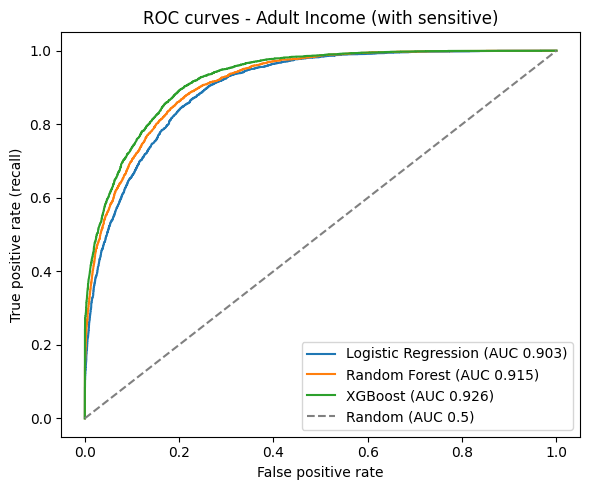

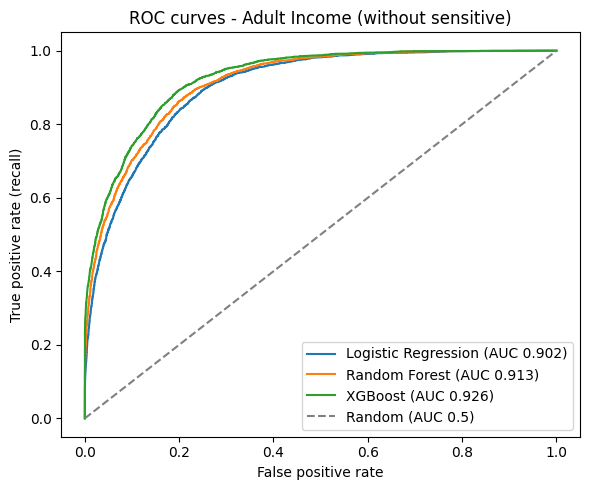

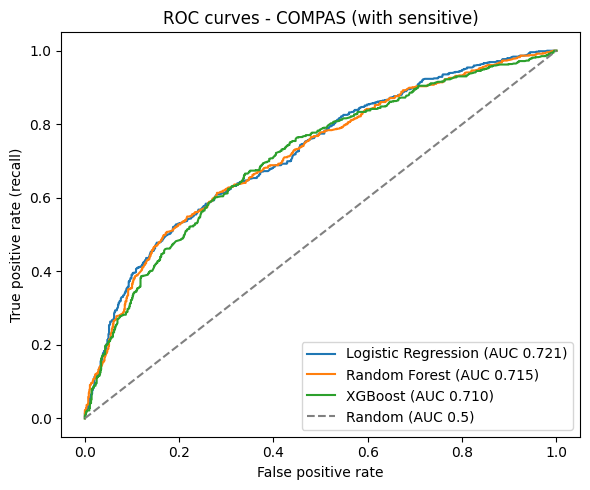

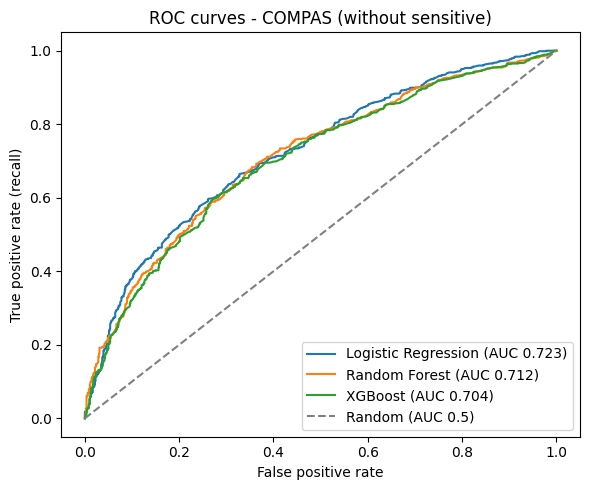

In [8]:
for name, (_, split) in prepared.items():
    save_performance_figures(fitted[name], split, name)
    for setting in config.SETTINGS:
        display(plot_roc_curves(fitted[name], split, name, setting))

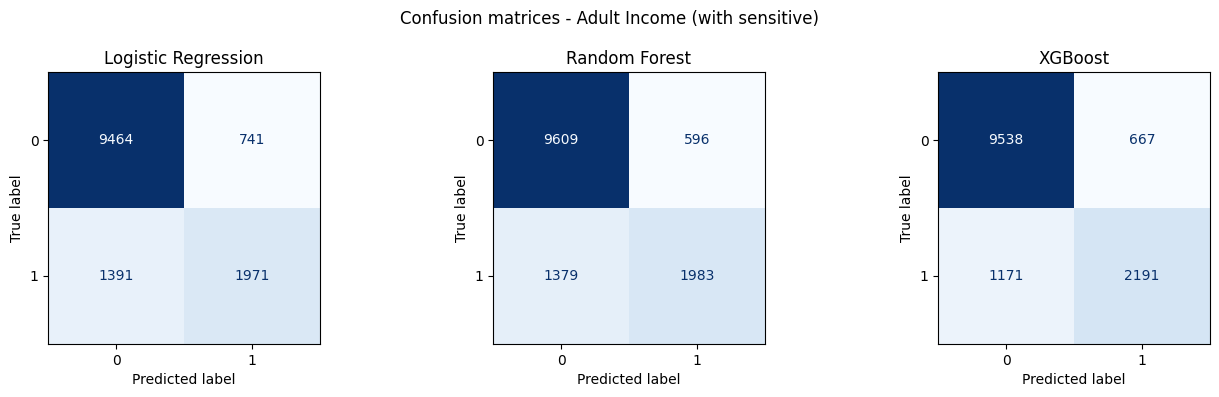

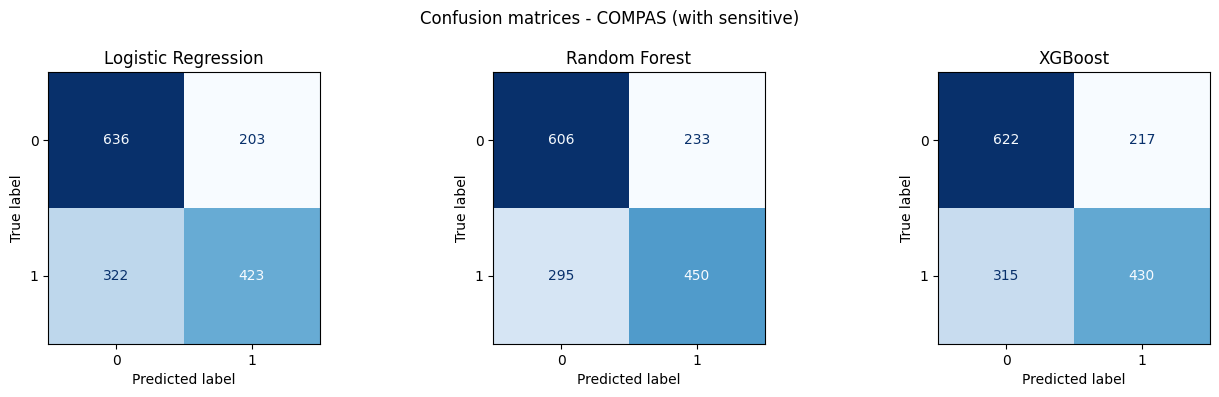

In [9]:
for name, (_, split) in prepared.items():
    display(plot_confusion_matrices(fitted[name], split, name, "with_sensitive"))

## Summary
* Twelve fitted pipelines are saved in `models/` and the metrics in `results/tables/performance.csv`.
* Compare the accuracy column with the expected ranges: Adult about 0.85, COMPAS about 0.65-0.70.
* COMPAS is much harder to predict than Adult (lower AUC): with only age, sex, race, charge degree and prior counts,
  a lot of re-offending is not predictable from the data.

Next: `03_fairness.ipynb` - are these models equally accurate and equally generous to each group?